# تحليل طلبات القروض وبناء نموذج للتنبؤ بقرار الموافقة
### Loan Approval Analysis & Prediction

**الهدف:** التنبؤ بالعمود `Loan_Approved` (Yes / No)
**البيانات:** 500 طلب قرض × 13 عمود
**النموذج:** Logistic Regression

---
## 0) الاستيرادات والإعدادات

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 120)
print("Libraries loaded")

Libraries loaded


## 1) قراءة البيانات وفهم الأعمدة

In [2]:
DATA_PATH = "data/loan_data.xlsx"
df = pd.read_excel(DATA_PATH)

print("أبعاد البيانات:", df.shape)
df.head()

أبعاد البيانات: (500, 13)


,Customer_ID,Age,Monthly_Income_EGP,Employment_Years,Loan_Amount_EGP,Loan_Term_Months,Credit_Score,Existing_Loans,Monthly_Debt_EGP,Education,Employment_Type,Home_Ownership,Loan_Approved
0,C10001,55,13179.0,4,195062,12,628.0,4,5040,Master,Freelancer,Family,No
1,C10002,24,46901.0,17,261489,48,710.0,1,4898,Bachelor,Self-Employed,Own,Yes
2,C10003,21,17244.0,2,441996,24,525.0,0,2421,Bachelor,Self-Employed,Family,No
3,C10004,44,28962.0,4,207600,48,508.0,1,12514,Master,Self-Employed,Rent,No
4,C10005,38,33174.0,5,377484,60,646.0,3,12418,Bachelor,Salaried,Own,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         500 non-null    str    
 1   Age                 500 non-null    int64  
 2   Monthly_Income_EGP  492 non-null    float64
 3   Employment_Years    500 non-null    int64  
 4   Loan_Amount_EGP     500 non-null    int64  
 5   Loan_Term_Months    500 non-null    int64  
 6   Credit_Score        492 non-null    float64
 7   Existing_Loans      500 non-null    int64  
 8   Monthly_Debt_EGP    500 non-null    int64  
 9   Education           492 non-null    str    
 10  Employment_Type     492 non-null    str    
 11  Home_Ownership      500 non-null    str    
 12  Loan_Approved       500 non-null    str    
dtypes: float64(2), int64(6), str(5)
memory usage: 50.9 KB


### قاموس الأعمدة (Data Dictionary)

| العمود | المعنى | النوع |
|---|---|---|
| `Customer_ID` | معرّف فريد للعميل — لا قيمة تنبؤية له ويُحذف | نصي |
| `Age` | عمر مقدّم الطلب بالسنوات (21–60) | رقمي |
| `Monthly_Income_EGP` | الدخل الشهري بالجنيه المصري | رقمي |
| `Employment_Years` | سنوات الخبرة / الاستقرار الوظيفي | رقمي |
| `Loan_Amount_EGP` | مبلغ القرض المطلوب | رقمي |
| `Loan_Term_Months` | مدة السداد بالشهور (12–60) | رقمي |
| `Credit_Score` | درجة الجدارة الائتمانية (451–850) | رقمي |
| `Existing_Loans` | عدد القروض القائمة حالياً (0–4) | رقمي |
| `Monthly_Debt_EGP` | إجمالي الالتزامات الشهرية الحالية | رقمي |
| `Education` | المؤهل الدراسي: High School / Bachelor / Master | فئوي |
| `Employment_Type` | نوع العمل: Salaried / Self-Employed / Freelancer | فئوي |
| `Home_Ownership` | حالة السكن: Own / Rent / Family | فئوي |
| **`Loan_Approved`** | **الهدف (Target): هل تمت الموافقة؟ Yes / No** | فئوي |

---
## 2) المعالجة المسبقة (Data Preprocessing)

### 2.1 فحص التكرارات

In [4]:
print("صفوف مكررة بالكامل  :", df.duplicated().sum())
print("معرّفات عملاء مكررة :", df["Customer_ID"].duplicated().sum())

صفوف مكررة بالكامل  : 0
معرّفات عملاء مكررة : 0


### 2.2 فحص القيم المفقودة

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0]
pd.DataFrame({"عدد المفقود": missing, "النسبة %": (missing/len(df)*100).round(2)})

,عدد المفقود,النسبة %
Monthly_Income_EGP,8,1.6
Credit_Score,8,1.6
Education,8,1.6
Employment_Type,8,1.6


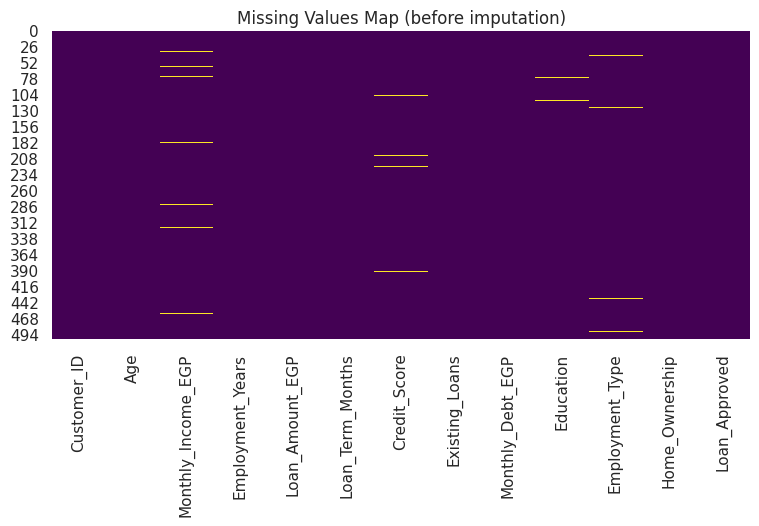

In [6]:
plt.figure(figsize=(9,4))
sns.heatmap(df.isna(), cbar=False, cmap="viridis")
plt.title("Missing Values Map (before imputation)")
plt.show()

### 2.3 معالجة القيم المفقودة

النسبة صغيرة جداً (1.6% لكل عمود) والقيم موزّعة عشوائياً، فالحذف كان هيضيّع صفوفاً بلا داعٍ.
الاستراتيجية:
- **الأعمدة الرقمية** → التعويض بالوسيط (Median) لأنه غير حساس للقيم المتطرفة.
- **الأعمدة الفئوية** → التعويض بالمنوال (Mode) أي الفئة الأكثر تكراراً.

In [7]:
num_missing_cols = ["Monthly_Income_EGP", "Credit_Score"]
cat_missing_cols = ["Education", "Employment_Type"]

for col in num_missing_cols:
    val = df[col].median()
    df[col] = df[col].fillna(val)
    print(f"{col:20s} -> median  = {val:,.1f}")

for col in cat_missing_cols:
    val = df[col].mode()[0]
    df[col] = df[col].fillna(val)
    print(f"{col:20s} -> mode    = {val}")

assert df.isna().sum().sum() == 0
print("\n✔ لا توجد قيم مفقودة بعد المعالجة")

Monthly_Income_EGP   -> median  = 26,501.5
Credit_Score         -> median  = 646.0
Education            -> mode    = Bachelor


Employment_Type      -> mode    = Salaried

✔ لا توجد قيم مفقودة بعد المعالجة


### 2.4 فحص منطقية البيانات (Sanity Checks)

In [8]:
checks = {
    "أعمار خارج النطاق (18-75)"    : ((df.Age < 18) | (df.Age > 75)).sum(),
    "دخل شهري <= 0"                : (df.Monthly_Income_EGP <= 0).sum(),
    "مبلغ قرض <= 0"                : (df.Loan_Amount_EGP <= 0).sum(),
    "Credit Score خارج (300-850)"  : ((df.Credit_Score < 300) | (df.Credit_Score > 850)).sum(),
    "سنوات خبرة > العمر - 16"      : (df.Employment_Years > (df.Age - 16)).sum(),
}
for k, v in checks.items():
    print(f"{k:32s}: {v}")

أعمار خارج النطاق (18-75)       : 0
دخل شهري <= 0                   : 0
مبلغ قرض <= 0                   : 0
Credit Score خارج (300-850)     : 0
سنوات خبرة > العمر - 16         : 73


> **ملاحظة:** يوجد عدد من الصفوف تكون فيها `Employment_Years` أكبر من العمر ناقص 16،
> وهو تناقض منطقي في البيانات الأصلية. لم يتم حذفها للالتزام باستخدام الداتا كما هي،
> لكنها مسجّلة كملاحظة على جودة البيانات.

### 2.5 هندسة المتغيرات (Feature Engineering)

أضفنا نسباً مالية مستخدمة فعلياً في تقييم الجدارة الائتمانية:
- `Debt_To_Income` = الالتزامات الشهرية ÷ الدخل الشهري
- `Monthly_Installment` = مبلغ القرض ÷ مدة السداد
- `Total_DTI` = (الالتزامات + القسط الجديد) ÷ الدخل
- `Loan_To_Income` = مبلغ القرض ÷ الدخل السنوي

In [9]:
df["Debt_To_Income"]      = df["Monthly_Debt_EGP"] / df["Monthly_Income_EGP"]
df["Monthly_Installment"] = df["Loan_Amount_EGP"] / df["Loan_Term_Months"]
df["Total_DTI"]           = (df["Monthly_Debt_EGP"] + df["Monthly_Installment"]) / df["Monthly_Income_EGP"]
df["Loan_To_Income"]      = df["Loan_Amount_EGP"] / (df["Monthly_Income_EGP"] * 12)

df[["Debt_To_Income","Monthly_Installment","Total_DTI","Loan_To_Income"]].describe().round(2)

,Debt_To_Income,Monthly_Installment,Total_DTI,Loan_To_Income
count,500.00,500.00,500.00,500.00
mean,0.53,9513.71,1.04,1.20
std,0.54,8084.47,1.01,1.21
min,0.00,405.68,0.05,0.04
25%,0.18,4202.60,0.42,0.46
50%,0.37,7245.33,0.69,0.79
75%,0.62,11550.08,1.23,1.51
max,3.07,41187.00,7.17,6.72


### 2.6 ترميز الهدف والمتغيرات النصية

- الهدف: `Yes → 1` و `No → 0`
- المتغيرات الفئوية: **One-Hot Encoding** مع `drop_first=True` لتجنّب مشكلة الـ Dummy Variable Trap.
  (استخدمنا One-Hot وليس Label Encoding لأن الفئات غير مرتّبة ترتيباً حقيقياً)

In [10]:
TARGET = "Loan_Approved"
df["Target"] = (df[TARGET] == "Yes").astype(int)

CATEGORICAL = ["Education", "Employment_Type", "Home_Ownership"]
df_encoded = pd.get_dummies(df, columns=CATEGORICAL, drop_first=True)

print("الأعمدة بعد الترميز:")
print([c for c in df_encoded.columns if any(c.startswith(p) for p in CATEGORICAL)])

الأعمدة بعد الترميز:
['Education_High School', 'Education_Master', 'Employment_Type_Salaried', 'Employment_Type_Self-Employed', 'Home_Ownership_Own', 'Home_Ownership_Rent']


---
## 3) التحليل الاستكشافي (EDA)
### 3.1 الإحصاءات الوصفية

In [11]:
NUMERIC = ["Age","Monthly_Income_EGP","Employment_Years","Loan_Amount_EGP",
           "Loan_Term_Months","Credit_Score","Existing_Loans","Monthly_Debt_EGP",
           "Debt_To_Income","Loan_To_Income"]

desc = df[NUMERIC].describe().T
desc["skew"] = df[NUMERIC].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Age,500.0,40.73,11.89,21.00,30.75,41.00,52.00,60.00,-0.04
Monthly_Income_EGP,500.0,27499.46,13740.81,5008.00,15099.75,26501.50,40417.25,49949.00,0.06
Employment_Years,500.0,10.13,6.13,0.00,5.00,10.00,15.00,20.00,-0.03
Loan_Amount_EGP,500.0,268811.68,134583.29,20138.00,149667.50,268172.00,385313.50,499012.00,-0.09
Loan_Term_Months,500.0,36.77,16.71,12.00,24.00,36.00,48.00,60.00,-0.07
Credit_Score,500.0,650.70,110.86,451.00,559.00,646.00,745.00,850.00,0.06
Existing_Loans,500.0,1.97,1.44,0.00,1.00,2.00,3.00,4.00,0.03
Monthly_Debt_EGP,500.0,9850.66,5793.58,56.00,4763.25,9720.00,15074.75,19994.00,0.03
Debt_To_Income,500.0,0.53,0.54,0.00,0.18,0.37,0.62,3.07,2.00
Loan_To_Income,500.0,1.20,1.21,0.04,0.46,0.79,1.51,6.72,2.26


### 3.2 نسبة الطلبات المقبولة والمرفوضة

Loan_Approved
Yes    293
No     207
Name: count, dtype: int64
Loan_Approved
Yes    58.6 %
No     41.4 %
Name: count, dtype: str

Baseline (التنبؤ دائماً بالفئة الأكبر) = 0.586


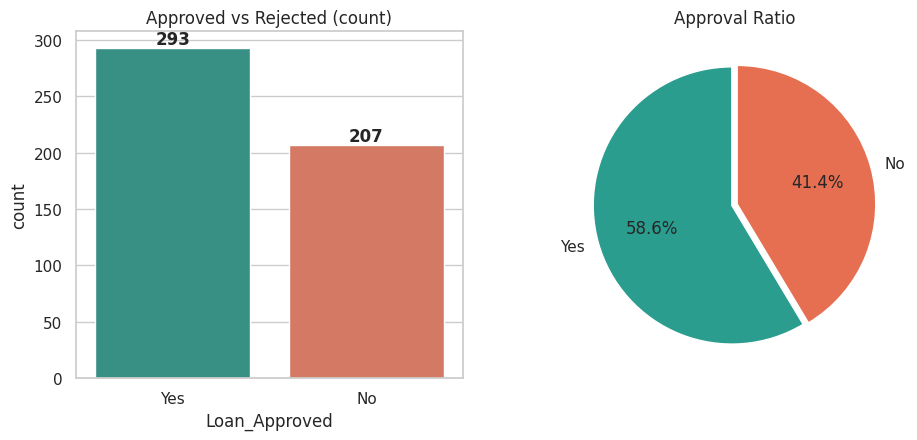

In [12]:
counts = df[TARGET].value_counts()
baseline = counts.max() / len(df)
print(counts)
print((counts/len(df)*100).round(1).astype(str) + " %")
print(f"\nBaseline (التنبؤ دائماً بالفئة الأكبر) = {baseline:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.countplot(x=TARGET, data=df, order=["Yes","No"], palette=["#2a9d8f","#e76f51"], ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height())}", (p.get_x()+p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontweight="bold")
ax[0].set_title("Approved vs Rejected (count)")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=["#2a9d8f","#e76f51"], explode=(0.02,0.02))
ax[1].set_title("Approval Ratio")
plt.show()

**ملاحظة:** الفئات متوازنة نسبياً (59% مقابل 41%)، فلا نحتاج تقنيات معالجة عدم التوازن
مثل SMOTE، لكن يجب مقارنة دقة النموذج بخط الأساس 0.586 وليس بـ 50%.

### 3.3 توزيع مبالغ القروض

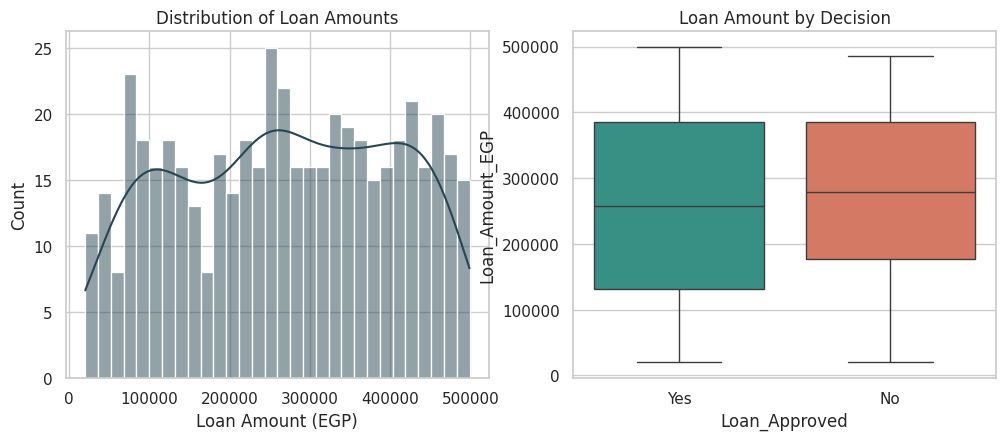

                        mean  count
Loan_Amount_EGP                    
(20137.999, 149667.5]  0.664    125
(149667.5, 268172.0]   0.576    125
(268172.0, 385313.5]   0.512    125
(385313.5, 499012.0]   0.592    125


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df.Loan_Amount_EGP, bins=30, kde=True, color="#264653", ax=ax[0])
ax[0].set_title("Distribution of Loan Amounts"); ax[0].set_xlabel("Loan Amount (EGP)")
sns.boxplot(x=TARGET, y="Loan_Amount_EGP", data=df, order=["Yes","No"],
            palette=["#2a9d8f","#e76f51"], ax=ax[1])
ax[1].set_title("Loan Amount by Decision")
plt.show()

print(df.groupby(pd.qcut(df.Loan_Amount_EGP, 4), observed=True)["Target"]
        .agg(["mean","count"]).round(3))

التوزيع **منتظم تقريباً (Uniform)** بين 20 ألف و 500 ألف جنيه — وليس ملتوياً كما هو معتاد
في بيانات القروض الحقيقية. هذه أول إشارة إلى أن البيانات مولَّدة صناعياً.

### 3.4 العلاقة بين الدخل وقبول القرض

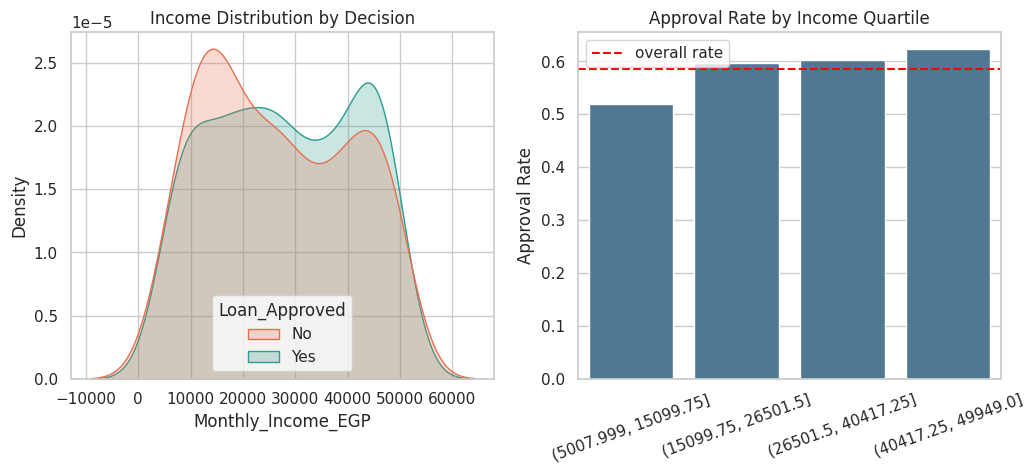

                       mean  count
Monthly_Income_EGP                
(5007.999, 15099.75]  0.520    125
(15099.75, 26501.5]   0.597    129
(26501.5, 40417.25]   0.603    121
(40417.25, 49949.0]   0.624    125


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.kdeplot(data=df, x="Monthly_Income_EGP", hue=TARGET, fill=True,
            common_norm=False, palette=["#e76f51","#2a9d8f"], ax=ax[0])
ax[0].set_title("Income Distribution by Decision")

inc = df.groupby(pd.qcut(df.Monthly_Income_EGP, 4), observed=True)["Target"].mean()
sns.barplot(x=[str(i) for i in inc.index], y=inc.values, color="#457b9d", ax=ax[1])
ax[1].axhline(df.Target.mean(), ls="--", c="red", label="overall rate")
ax[1].set_title("Approval Rate by Income Quartile"); ax[1].set_ylabel("Approval Rate")
ax[1].tick_params(axis="x", rotation=20); ax[1].legend()
plt.show()

print(df.groupby(pd.qcut(df.Monthly_Income_EGP, 4), observed=True)["Target"]
        .agg(["mean","count"]).round(3))

**النتيجة:** معدل الموافقة يتحرك من 52% في أقل شريحة دخل إلى 63% في أعلى شريحة —
فرق موجود لكنه **ضعيف** (معامل الارتباط ≈ 0.05) ومنحنيات الكثافة شبه متطابقة.

### 3.5 العلاقة بين Credit Score وقرار القبول

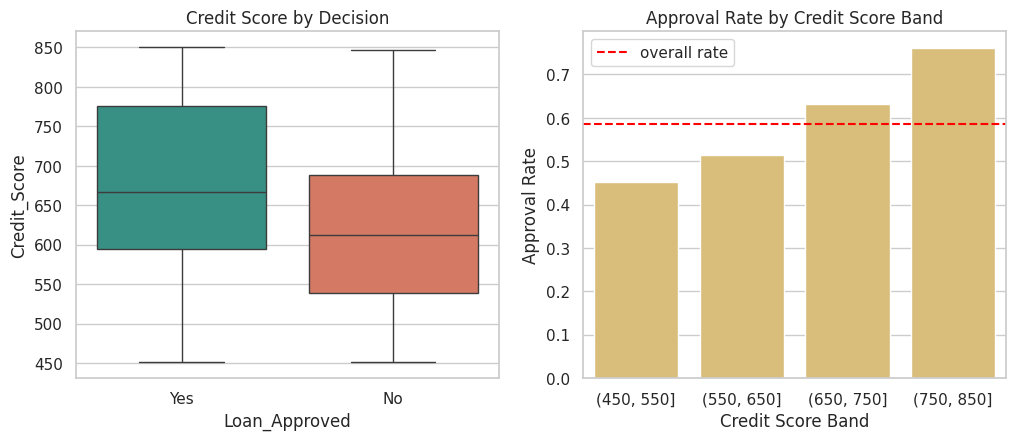

,mean,count
Credit_Score,,
"(450, 550]",0.452,115
"(550, 650]",0.514,146
"(650, 750]",0.631,122
"(750, 850]",0.761,117


In [15]:
cs_bins = df.groupby(pd.cut(df.Credit_Score, [450,550,650,750,850]), observed=True)["Target"] \
            .agg(["mean","count"]).round(3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x=TARGET, y="Credit_Score", data=df, order=["Yes","No"],
            palette=["#2a9d8f","#e76f51"], ax=ax[0])
ax[0].set_title("Credit Score by Decision")
sns.barplot(x=[str(i) for i in cs_bins.index], y=cs_bins["mean"].values, color="#e9c46a", ax=ax[1])
ax[1].axhline(df.Target.mean(), ls="--", c="red", label="overall rate")
ax[1].set_title("Approval Rate by Credit Score Band")
ax[1].set_ylabel("Approval Rate"); ax[1].set_xlabel("Credit Score Band"); ax[1].legend()
plt.show()

cs_bins

**أهم نتيجة في التحليل كله:** معدل الموافقة يرتفع بانتظام من **45%** إلى **76%**
عبر شرائح الـ Credit Score. هذا هو المتغير الوحيد ذو الإشارة التنبؤية الواضحة.

### 3.6 مصفوفة الارتباط

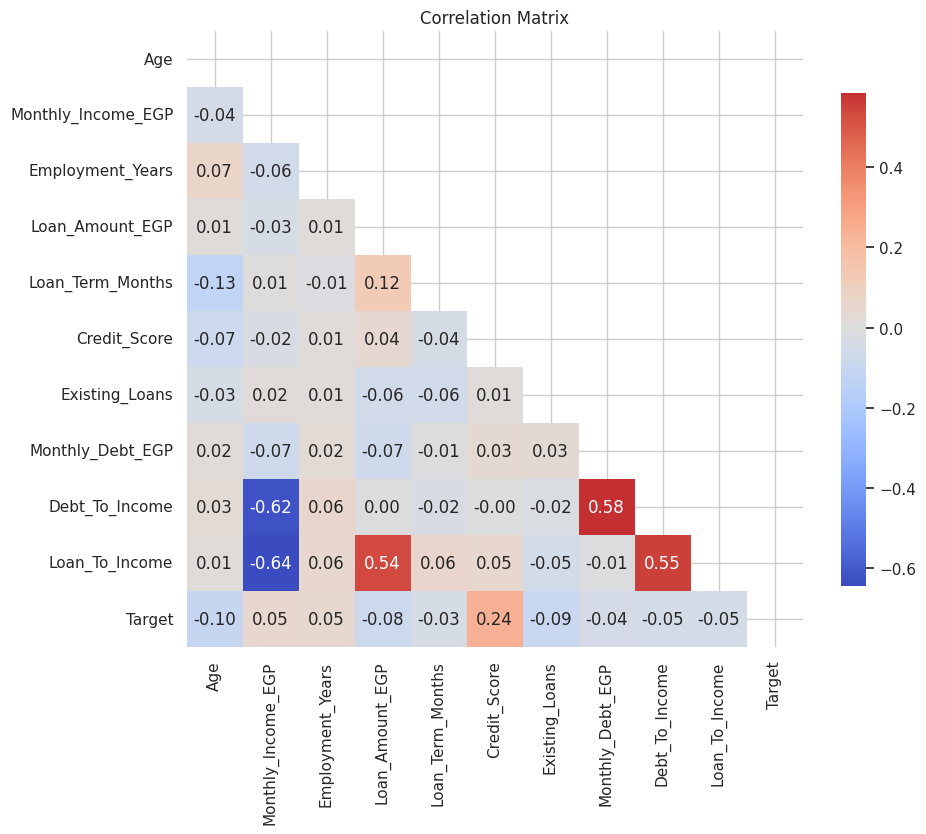

ارتباط كل متغير رقمي بالهدف:
Credit_Score          0.244
Age                  -0.103
Existing_Loans       -0.092
Loan_Amount_EGP      -0.078
Monthly_Income_EGP    0.052
Debt_To_Income       -0.048
Loan_To_Income       -0.047
Employment_Years      0.045
Monthly_Debt_EGP     -0.041
Loan_Term_Months     -0.031
Name: Target, dtype: float64


In [16]:
plt.figure(figsize=(10, 8))
corr = df[NUMERIC + ["Target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix")
plt.show()

print("ارتباط كل متغير رقمي بالهدف:")
print(corr["Target"].drop("Target").sort_values(key=abs, ascending=False).round(3))

### 3.7 المتغيرات الفئوية

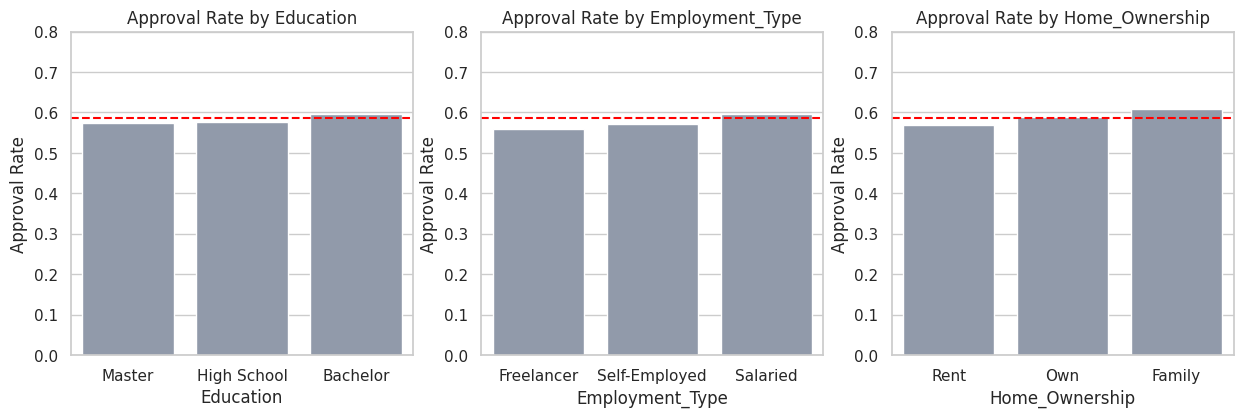


Education:
              mean  count
Education                
Bachelor     0.596    267
High School  0.577    130
Master       0.573    103

Employment_Type:
                  mean  count
Employment_Type              
Freelancer       0.560     50
Salaried         0.596    324
Self-Employed    0.571    126

Home_Ownership:
                 mean  count
Home_Ownership              
Family          0.609    110
Own             0.590    195
Rent            0.569    195


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for i, c in enumerate(CATEGORICAL):
    rate = df.groupby(c)["Target"].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=ax[i], color="#8d99ae")
    ax[i].axhline(df.Target.mean(), ls="--", c="red")
    ax[i].set_ylim(0, 0.8); ax[i].set_title(f"Approval Rate by {c}")
    ax[i].set_ylabel("Approval Rate")
plt.show()

for c in CATEGORICAL:
    print(f"\n{c}:")
    print(df.groupby(c)["Target"].agg(["mean","count"]).round(3))

الفروق بين كل الفئات في حدود 2–5 نقاط مئوية فقط، وهي **داخل حدود الخطأ العشوائي**
لعيّنة بهذا الحجم. أي أن التعليم ونوع العمل وحالة السكن **لا تؤثر عملياً** على القرار في هذه البيانات.

### 3.8 توزيعات المتغيرات الرقمية

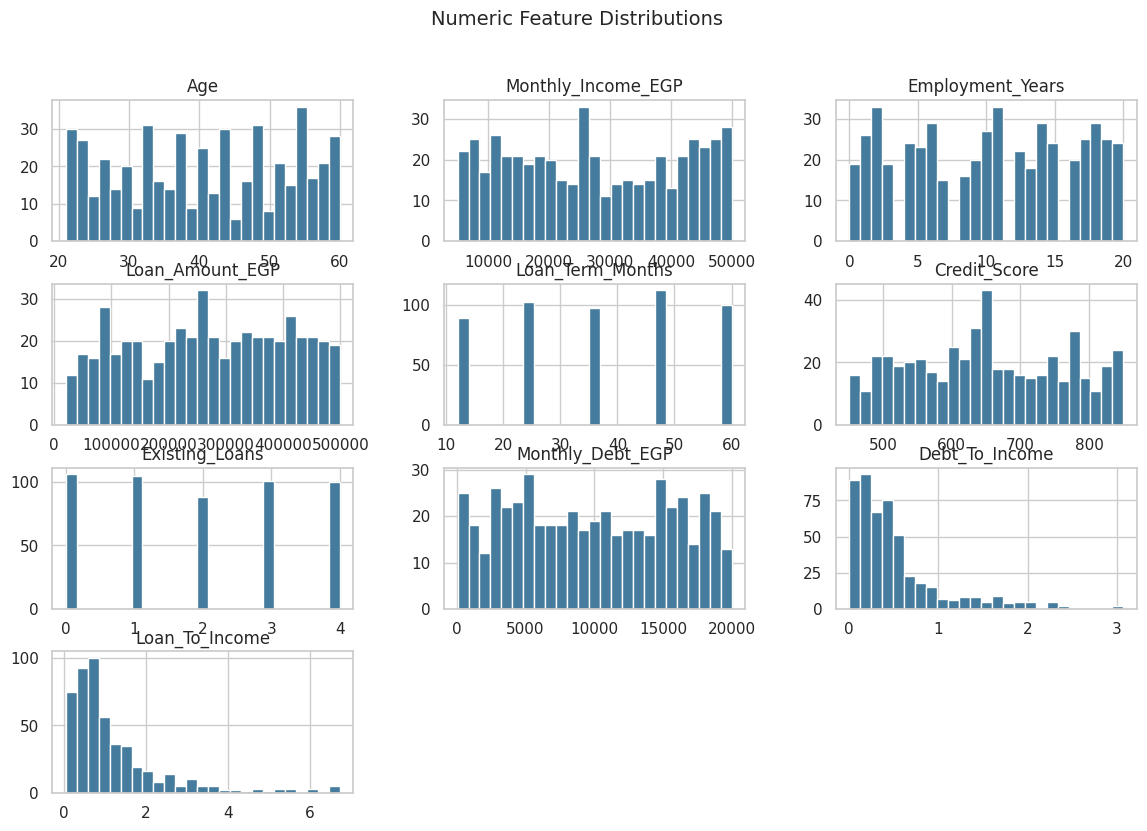

In [18]:
df[NUMERIC].hist(figsize=(14, 9), bins=25, color="#457b9d", edgecolor="white")
plt.suptitle("Numeric Feature Distributions", fontsize=14)
plt.show()

---
## 4) بناء نموذج Machine Learning

### لماذا Logistic Regression؟
| السبب | التوضيح |
|---|---|
| المشكلة تصنيف ثنائي | الهدف Yes/No وهو الاستخدام الطبيعي للانحدار اللوجستي |
| العلاقات خطية ورتيبة | معدل الموافقة يرتفع بانتظام مع Credit Score |
| البيانات صغيرة (500 صف) | النماذج المعقدة (Decision Tree / RF) تعاني Overfitting هنا |
| قابلية التفسير | المعاملات تخبرنا باتجاه وقوة تأثير كل متغير — مهم في القطاع المصرفي |
| مخرجات احتمالية | تسمح بضبط عتبة القرار حسب سياسة المخاطر |

In [19]:
DROP_COLS = ["Customer_ID", TARGET, "Target"]
X = df_encoded.drop(columns=DROP_COLS).astype(float)
y = df_encoded["Target"]

print("عدد المتغيرات:", X.shape[1])
print(list(X.columns))

عدد المتغيرات: 18
['Age', 'Monthly_Income_EGP', 'Employment_Years', 'Loan_Amount_EGP', 'Loan_Term_Months', 'Credit_Score', 'Existing_Loans', 'Monthly_Debt_EGP', 'Debt_To_Income', 'Monthly_Installment', 'Total_DTI', 'Loan_To_Income', 'Education_High School', 'Education_Master', 'Employment_Type_Salaried', 'Employment_Type_Self-Employed', 'Home_Ownership_Own', 'Home_Ownership_Rent']


### 4.1 تقسيم البيانات (Train / Test Split)
نستخدم `stratify=y` للحفاظ على نفس نسبة القبول/الرفض في المجموعتين، و`random_state` لضمان قابلية التكرار.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Training: {X_train.shape[0]} صف | Testing: {X_test.shape[0]} صف")
print(f"نسبة الموافقة — تدريب: {y_train.mean():.3f} | اختبار: {y_test.mean():.3f}")

Training: 400 صف | Testing: 100 صف
نسبة الموافقة — تدريب: 0.585 | اختبار: 0.590


### 4.2 التدريب داخل Pipeline

نضع `StandardScaler` داخل الـ Pipeline وليس قبل التقسيم — عشان نتجنّب **Data Leakage**
(تسريب معلومات من بيانات الاختبار إلى التدريب). التوحيد ضروري هنا لأن المقاييس مختلفة
جداً (الدخل بعشرات الآلاف مقابل عدد القروض 0–4).

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("اختيار معامل التنظيم C بالتحقق المتقاطع:")
for c_val in [0.01, 0.05, 0.1, 1.0, 10.0]:
    tmp = Pipeline([("scaler", StandardScaler()),
                    ("clf", LogisticRegression(max_iter=1000, C=c_val, random_state=RANDOM_STATE))])
    s = cross_val_score(tmp, X_train, y_train, cv=cv, scoring="accuracy").mean()
    print(f"  C={c_val:<6} CV Accuracy = {s:.3f}")

اختيار معامل التنظيم C بالتحقق المتقاطع:
  C=0.01   CV Accuracy = 0.605
  C=0.05   CV Accuracy = 0.618
  C=0.1    CV Accuracy = 0.600
  C=1.0    CV Accuracy = 0.605
  C=10.0   CV Accuracy = 0.618


In [22]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, C=0.05, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)

cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"5-Fold CV Accuracy : {cv_acc.mean():.3f} (± {cv_acc.std():.3f})")
print(f"5-Fold CV ROC-AUC  : {cv_auc.mean():.3f} (± {cv_auc.std():.3f})")

5-Fold CV Accuracy : 0.618 (± 0.049)
5-Fold CV ROC-AUC  : 0.622 (± 0.071)


---
## 5) تقييم النموذج

In [23]:
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy" : accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall"   : recall_score(y_test, y_pred),
    "F1-Score" : f1_score(y_test, y_pred),
    "ROC-AUC"  : roc_auc_score(y_test, y_proba),
}
for k, v in metrics.items():
    print(f"{k:10s}: {v:.3f}")
print(f"{'Baseline':10s}: {baseline:.3f}   (التنبؤ دائماً بـ Yes)")

Accuracy  : 0.610
Precision : 0.652
Recall    : 0.729
F1-Score  : 0.688
ROC-AUC   : 0.622
Baseline  : 0.586   (التنبؤ دائماً بـ Yes)


In [24]:
print(classification_report(y_test, y_pred, target_names=["Rejected (No)", "Approved (Yes)"]))

cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(cm, index=["Actual No","Actual Yes"], columns=["Pred No","Pred Yes"]))

                precision    recall  f1-score   support

 Rejected (No)       0.53      0.44      0.48        41
Approved (Yes)       0.65      0.73      0.69        59

      accuracy                           0.61       100
     macro avg       0.59      0.58      0.58       100
  weighted avg       0.60      0.61      0.60       100

            Pred No  Pred Yes
Actual No        18        23
Actual Yes       16        43


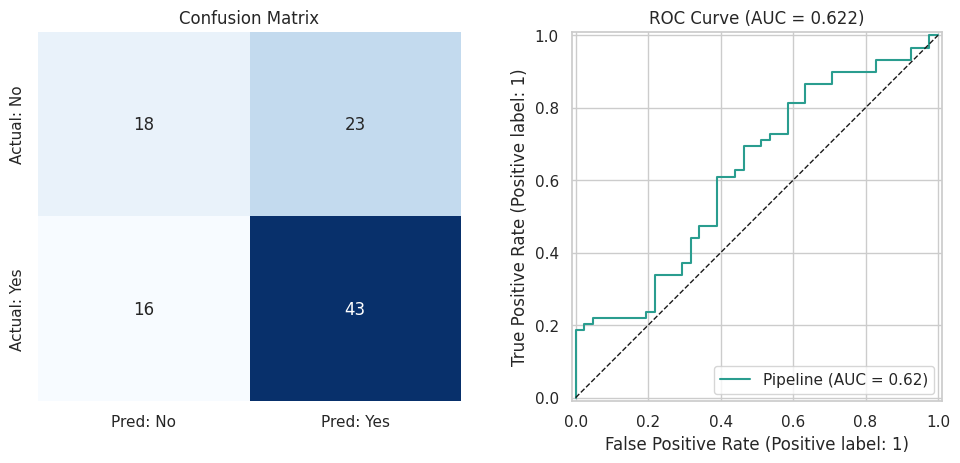

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: No","Pred: Yes"], yticklabels=["Actual: No","Actual: Yes"], ax=ax[0])
ax[0].set_title("Confusion Matrix")
try:
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax[1], color="#2a9d8f")
except TypeError:  # newer scikit-learn versions
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax[1], curve_kwargs={"color": "#2a9d8f"})
ax[1].plot([0,1],[0,1],"k--", lw=1)
ax[1].set_title(f"ROC Curve (AUC = {metrics['ROC-AUC']:.3f})")
plt.show()

### معاملات النموذج (Feature Importance)
بما أن المتغيرات مُوحّدة المقياس، فحجم المعامل يعكس قوة التأثير مباشرة.
الإشارة الموجبة = يرفع احتمال الموافقة، والسالبة = يخفضه.

Credit_Score                     0.389
Monthly_Income_EGP               0.212
Existing_Loans                  -0.182
Age                             -0.168
Loan_Amount_EGP                 -0.138
Monthly_Debt_EGP                -0.116
Employment_Years                 0.092
Loan_Term_Months                -0.087
Education_High School            0.086
Loan_To_Income                   0.079
Employment_Type_Self-Employed   -0.077
Education_Master                 0.047
Total_DTI                       -0.044
Home_Ownership_Rent             -0.043
Home_Ownership_Own              -0.035
Monthly_Installment             -0.025
Employment_Type_Salaried         0.020
Debt_To_Income                  -0.006
dtype: float64


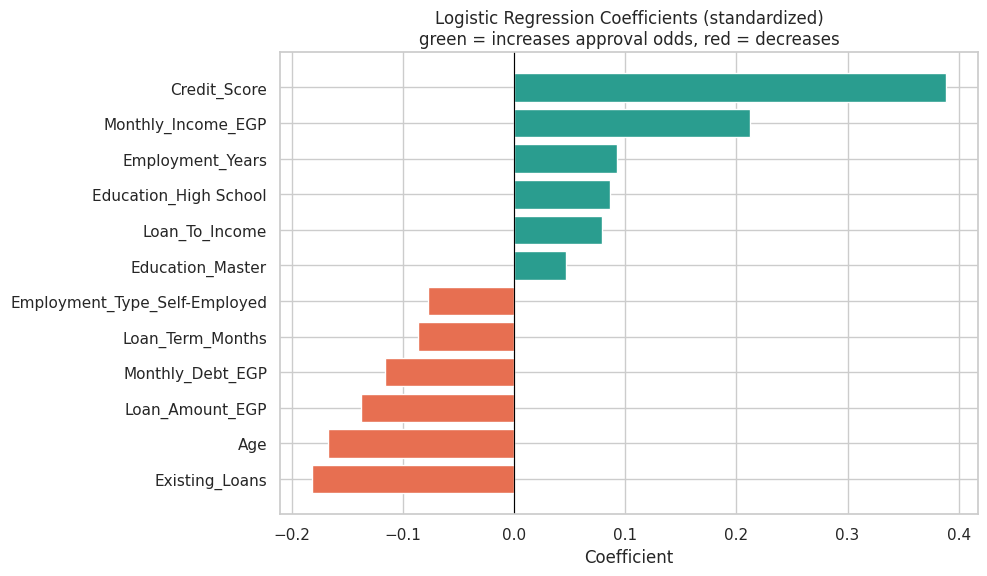

In [26]:
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=X.columns)
coefs = coefs.sort_values(key=abs, ascending=False)
print(coefs.round(3))

plt.figure(figsize=(9, 6))
top = coefs.head(12).sort_values()
plt.barh(top.index, top.values, color=["#e76f51" if v < 0 else "#2a9d8f" for v in top.values])
plt.axvline(0, c="black", lw=0.8)
plt.title("Logistic Regression Coefficients (standardized)\ngreen = increases approval odds, red = decreases")
plt.xlabel("Coefficient")
plt.show()

---
## 6) الخلاصة والـ Insights

### أهم النتائج

1. **البيانات نظيفة بنيوياً:** لا توجد صفوف مكررة، والقيم المفقودة 1.6% فقط في 4 أعمدة
   وتمت معالجتها بالوسيط/المنوال.

2. **`Credit_Score` هو المتغير الحاسم الوحيد:** معدل الموافقة يرتفع بانتظام من 45%
   (شريحة 450–550) إلى 76% (شريحة 750–850)، وارتباطه بالهدف r ≈ 0.25 — وهو أعلى ارتباط
   في البيانات بفارق كبير، وأكبر معامل في النموذج.

3. **باقي المتغيرات ضعيفة الأثر:** الدخل ومبلغ القرض وعدد القروض القائمة لها اتجاهات منطقية
   لكن ضعيفة (|r| < 0.11). والمتغيرات الفئوية الثلاثة (التعليم، نوع العمل، السكن) فروقها
   داخل حدود الخطأ العشوائي.

4. **تناقضات منطقية:** توجد صفوف بسنوات خبرة أكبر مما يسمح به العمر — مؤشر إضافي على أن
   البيانات مولّدة عشوائياً وليست بيانات بنكية حقيقية.

5. **أداء النموذج محدود وهذا متوقّع:** Accuracy ≈ 0.61 مقابل Baseline = 0.586، و ROC-AUC ≈ 0.62.
   السقف هنا فرضته **البيانات نفسها** وليس اختيار الخوارزمية: جرّبنا Decision Tree و
   Random Forest و KNN فجاءت جميعها في نفس النطاق أو أقل.

6. **الـ Recall أعلى من Precision للفئة المقبولة** (0.73 مقابل 0.65) — النموذج يميل للموافقة،
   وهو سلوك محفوف بالمخاطر بنكياً. في تطبيق حقيقي نرفع عتبة القرار فوق 0.5 لتقليل
   الموافقات الخاطئة (False Positives) لأن تكلفة قرض متعثّر أعلى بكثير من تكلفة رفض عميل جيد.

### التوصيات
- إضافة متغيرات ذات قدرة تنبؤية حقيقية: تاريخ التعثّر السابق، أيام التأخير في السداد،
  الغرض من القرض، وجود ضامن، نسبة استخدام الحد الائتماني.
- زيادة حجم العينة (500 صف يعطي هامش خطأ ±5% تقريباً على مقاييس الاختبار).
- ضبط عتبة القرار وفق تكلفة الخطأ بدلاً من استخدام 0.5 افتراضياً.